In [1]:
import json
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # permet "from src..." depuis notebooks/

import matplotlib.pyplot as plt
import numpy as np

from src.data.load import load_cmapss, FEATURE_SENSORS
from src.data.labels import make_labels

In [2]:
df = make_labels(load_cmapss("train"), horizon=30)

with open("../configs/split_FD001.json", encoding="utf-8") as f:
    split = json.load(f)

dev = df[df["unit_id"].isin(split["train_units"])]   # les 80 moteurs
X = dev[FEATURE_SENSORS]
y = dev["target"]
groups = dev["unit_id"]

print(X.shape, f"taux de positifs : {y.mean():.3f}")

(16390, 21) taux de positifs : 0.151


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
cv = GroupKFold(n_splits=5)

# Score par pli : pour voir la stabilité
scores = cross_validate(model, X, y, groups=groups, cv=cv,
                        scoring=["average_precision", "recall", "precision", "f1"])
for name in ["average_precision", "recall", "precision", "f1"]:
    s = scores[f"test_{name}"]
    print(f"{name:18s} {s.mean():.3f} ± {s.std():.3f}")

# Probabilités "hors pli" : chaque ligne est prédite par un modèle qui ne l'a jamais vue
proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]

average_precision  0.950 ± 0.014
recall             0.944 ± 0.014
precision          0.732 ± 0.067
f1                 0.822 ± 0.043


PR-AUC (hors pli) : 0.946
Niveau du hasard  : 0.151
[[13024   886]
 [  140  2340]]
              precision    recall  f1-score   support

           0      0.989     0.936     0.962     13910
           1      0.725     0.944     0.820      2480

    accuracy                          0.937     16390
   macro avg      0.857     0.940     0.891     16390
weighted avg      0.949     0.937     0.941     16390



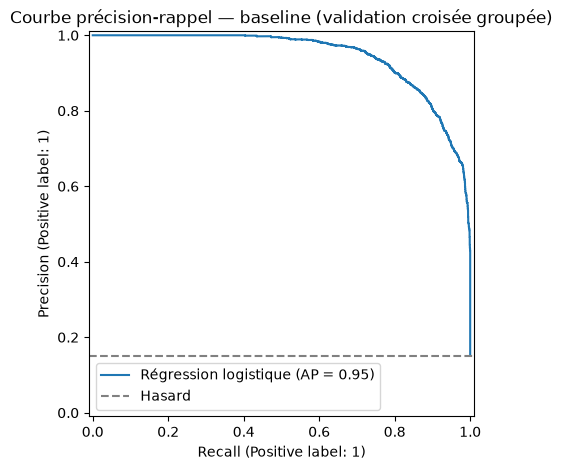

In [4]:
from sklearn.metrics import (average_precision_score, classification_report,
                             confusion_matrix, PrecisionRecallDisplay)

print(f"PR-AUC (hors pli) : {average_precision_score(y, proba):.3f}")
print(f"Niveau du hasard  : {y.mean():.3f}")

y_pred = (proba >= 0.5).astype(int)
print(confusion_matrix(y, y_pred))
print(classification_report(y, y_pred, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y, proba, ax=ax, name="Régression logistique")
ax.axhline(y.mean(), linestyle="--", color="grey", label="Hasard")
ax.set_title("Courbe précision-rappel — baseline (validation croisée groupée)")
ax.legend()
fig.savefig("../reports/figures/pr_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
) #sans classweight
cv = GroupKFold(n_splits=5)

# Score par pli : pour voir la stabilité
scores = cross_validate(model, X, y, groups=groups, cv=cv,
                        scoring=["average_precision", "recall", "precision", "f1"])
for name in ["average_precision", "recall", "precision", "f1"]:
    s = scores[f"test_{name}"]
    print(f"{name:18s} {s.mean():.3f} ± {s.std():.3f}")

# Probabilités "hors pli" : chaque ligne est prédite par un modèle qui ne l'a jamais vue
proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method="predict_proba")[:, 1]

average_precision  0.950 ± 0.014
recall             0.841 ± 0.031
precision          0.876 ± 0.050
f1                 0.857 ± 0.023


In [6]:
import pandas as pd

models = {
    "Régression logistique": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000),
    ),
    "Régression logistique + class_weight": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000),
    ),
}

rows = [{
    "Modèle": "Hasard (taux de positifs)",
    "PR-AUC": y.mean(),
    "PR-AUC écart-type": None,
    "Rappel": None,
    "Précision": None,
}]

for name, model in models.items():
    scores = cross_validate(
        model, X, y, groups=groups, cv=cv,
        scoring=["average_precision", "recall", "precision"],
    )
    rows.append({
        "Modèle": name,
        "PR-AUC": scores["test_average_precision"].mean(),
        "PR-AUC écart-type": scores["test_average_precision"].std(),
        "Rappel": scores["test_recall"].mean(),
        "Précision": scores["test_precision"].mean(),
    })

results = pd.DataFrame(rows).round(3)
results

,Modèle,PR-AUC,PR-AUC écart-type,Rappel,Précision
0,Hasard (taux de positifs),0.151,NaN,NaN,NaN
1,Régression logistique,0.950,0.014,0.841,0.876
2,Régression logistique + class_weight,0.950,0.014,0.944,0.732


## Conclusion — baseline

**Résultats (validation croisée groupée, 5 plis, 80 moteurs)**

| Modèle | PR-AUC | Rappel (seuil 0,5) | Précision (seuil 0,5) |
|---|---|---|---|
| Hasard (taux de positifs) | [0.151] | — | — |
| Régression logistique | [0.950] ± [0.014] | [0.841] | [0.876] |
| Régression logistique + `class_weight="balanced"` | [0.950] ± [0.014] | [0.944] | [0.732] |

**Observations**
- La baseline atteint une PR-AUC de [0.946], nettement au-dessus du hasard ([0.151]) : les capteurs bruts contiennent déjà un signal fort sur l'approche de la panne.
- `class_weight="balanced"` fait passer le rappel de [0.841] à [0.944], au prix d'une précision qui passe de [0.876] à [0.732]. La PR-AUC bouge peu : la pondération déplace surtout le compromis au seuil de 0,5, sans rendre le modèle meilleur pour classer les moteurs.
- Les scores sont [stables / variables] d'un pli à l'autre (écart-type de [XX]), donc le résultat dépend [peu / sensiblement] des moteurs tirés.

**Limites**
- Le modèle ne voit qu'un cycle à la fois, alors que les capteurs sont très bruités : il ignore l'historique et la tendance du moteur.
- Le modèle est linéaire : il ne capte pas d'interactions entre capteurs.
- Le seuil de 0,5 est arbitraire et ne tient pas compte du coût réel d'une panne ratée.

**Pistes pour la semaine 2**
- Ajouter des moyennes et écarts-types glissants par moteur (fenêtres 5, 10, 20 cycles), calculés uniquement sur le passé.
- Comparer avec des modèles d'arbres (Random Forest, LightGBM).
- Choisir le seuil en minimisant un coût (faux négatif beaucoup plus cher qu'un faux positif).
- Suivre chaque expérience dans MLflow.